In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from src.data_loader import *
from src.models import *
from src.trainer import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Carregamento dos dados:

In [14]:
root = "pa3_dados"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Rodando em: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

label_to_idx, idx_to_label, class_names = get_class_mappings(root)
print(f"Total de classes carregadas: {len(class_names)}")

Rodando em: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
Total de classes carregadas: 21


In [15]:
# y_train = get_labels(root, labels_qtt=5)
# y_val   = get_labels(root, file_name="val")
# y_test  = get_labels(root, file_name="test_public")


# y_train_map = {
#     k: v["label"]
#     for k, v in y_train.set_index("image_id").to_dict(orient="index").items()
# }

# y_val_map = {
#     k: v["label"]
#     for k, v in y_val.set_index("image_id").to_dict(orient="index").items()
# }

# y_test_map = {
#     k: v["label"]
#     for k, v in y_test.set_index("image_id").to_dict(orient="index").items()
# }

In [16]:
# transform_unsupervised = transforms.Compose([
#     transforms.Resize((360, 512)), # Resize para um dimensionamento padrao
#     transforms.ToTensor(),
#     transforms.Grayscale()
# ])

# # Instancia os Datasets de treino, validacao e teste
# train_dataset = ENA24UnsupervisedDataset(
#     root_dir=root, 
#     split='train', 
#     transform=transform_unsupervised
# )
# val_dataset = ENA24UnsupervisedDataset(
#     root_dir=root, 
#     split='val', 
#     transform=transform_unsupervised
# )
# test_dataset = ENA24UnsupervisedDataset(
#     root_dir=root, 
#     split='test_public', 
#     transform=transform_unsupervised
# )

# # Cria os DataLoaders
# loader_params = {
#     "batch_size": 16, 
#     "shuffle": True,  # Para treino, embaralhamos os dados
#     "num_workers": 2, 
# }
# train_loader = DataLoader(train_dataset, **loader_params)
# val_loader   = DataLoader(val_dataset, **loader_params)
# test_loader  = DataLoader(test_dataset, **loader_params)


# # Testando um batch
# find = False
# for images, image_ids in train_loader:
#     for image, image_id in zip(images, image_ids):
#         label = y_train_map.get(image_id, None)
#         if label:
#             image = image.numpy().transpose((1, 2, 0))
#             image = np.clip(image, 0, 1)
#             plt.imshow(image)
#             plt.title(f"Label: {label}")
#             find = True
#             break
        
#     if find:
#         break

# Parte 0 — O piso:

### 0.0: Carregamento dos dados de treino (Supervisionados)

In [17]:
root = "pa3_dados"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Rodando em: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

label_to_idx, idx_to_label, class_names = get_class_mappings(root)
print(f"Total de classes carregadas: {len(class_names)}")

Rodando em: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
Total de classes carregadas: 21


### 0.1: Treinem um classificador supervisionado só com rotulos_5.csv (105 imagens), em duas versões: 

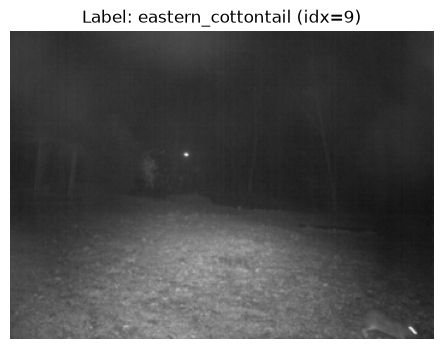

In [18]:
# Carrega o orçamento padrão de 5 rótulos por classe (105 imagens no treino)
train_loader_5, val_loader, test_loader = get_supervised_dataloaders(
    root_dir=root,
    labels_qtt=5,
    batch_size=16,
    img_size=(256, 352),
    num_workers=2,
    seed=42
)

# Visualizando uma amostra do train_loader_5 (revertendo a normalização do ImageNet para exibir as cores)
images, labels = next(iter(train_loader_5))
img_sample = images[0].permute(1, 2, 0).numpy()
img_sample = np.clip(img_sample * IMAGENET_STD + IMAGENET_MEAN, 0, 1)

plt.figure(figsize=(6, 4))
plt.imshow(img_sample)
plt.title(f"Label: {idx_to_label[labels[0].item()]} (idx={labels[0].item()})")
plt.axis("off")
plt.show()

#### (a) uma CNN pequena treinada do zero; 

In [19]:
cnn_zero = build_model("small_cnn", num_classes=21).to(device)
print(f"Treinando SmallCNN do zero ({count_parameters(cnn_zero):,} parâmetros)...")

cnn_zero, hist_cnn = train_model(
    model=cnn_zero,
    train_loader=train_loader_5,
    val_loader=val_loader,
    device=device,
    model_type="small_cnn",
    epochs=50,
    lr_head=1e-3,
    weight_decay=1e-2,
    save_path="checkpoints/piso_small_cnn_b5_s42.pt",
    seed=42
)

Treinando SmallCNN do zero (394,293 parâmetros)...
Época [01/50] Train Loss: 3.1481 | Train F1: 0.038 || Val Loss: 3.0388 | Val F1: 0.015 (Acc: 0.054) ⭐ [Novo Melhor Val F1]
Época [02/50] Train Loss: 2.8068 | Train F1: 0.150 || Val Loss: 3.0387 | Val F1: 0.017 (Acc: 0.059) ⭐ [Novo Melhor Val F1]
Época [03/50] Train Loss: 2.7551 | Train F1: 0.104 || Val Loss: 3.0304 | Val F1: 0.046 (Acc: 0.079) ⭐ [Novo Melhor Val F1]
Época [04/50] Train Loss: 2.6008 | Train F1: 0.163 || Val Loss: 2.9426 | Val F1: 0.086 (Acc: 0.134) ⭐ [Novo Melhor Val F1]
Época [05/50] Train Loss: 2.6082 | Train F1: 0.130 || Val Loss: 2.8976 | Val F1: 0.098 (Acc: 0.144) ⭐ [Novo Melhor Val F1]
Época [06/50] Train Loss: 2.5014 | Train F1: 0.154 || Val Loss: 2.8378 | Val F1: 0.142 (Acc: 0.183) ⭐ [Novo Melhor Val F1]
Época [10/50] Train Loss: 2.3860 | Train F1: 0.235 || Val Loss: 2.8498 | Val F1: 0.128 (Acc: 0.153)
Época [15/50] Train Loss: 2.2978 | Train F1: 0.215 || Val Loss: 2.9683 | Val F1: 0.107 (Acc: 0.139)
Época [19/5

#### (b) o backbone que vocês vão usar no resto do PA, partindo do ImageNet, com fine-tuning.

In [20]:
resnet_piso = build_model("resnet18", num_classes=21, pretrained=True).to(device)
print(f"Treinando ResNet-18 ImageNet ({count_parameters(resnet_piso):,} parâmetros)...")

resnet_piso, hist_resnet = train_model(
    model=resnet_piso,
    train_loader=train_loader_5,
    val_loader=val_loader,
    device=device,
    model_type="resnet18",
    epochs=40,
    lr_backbone=1e-4,
    lr_head=1e-3,
    weight_decay=1e-2,
    save_path="checkpoints/piso_resnet18_b5_s42.pt",
    seed=42
)

Treinando ResNet-18 ImageNet (11,187,285 parâmetros)...
Época [01/40] Train Loss: 3.2422 | Train F1: 0.054 || Val Loss: 2.8372 | Val F1: 0.130 (Acc: 0.168) [Novo Melhor Val F1]
Época [02/40] Train Loss: 2.0864 | Train F1: 0.547 || Val Loss: 2.4941 | Val F1: 0.263 (Acc: 0.282) [Novo Melhor Val F1]
Época [03/40] Train Loss: 1.4582 | Train F1: 0.712 || Val Loss: 2.2498 | Val F1: 0.273 (Acc: 0.282) [Novo Melhor Val F1]
Época [04/40] Train Loss: 1.0104 | Train F1: 0.901 || Val Loss: 2.1591 | Val F1: 0.296 (Acc: 0.282) [Novo Melhor Val F1]
Época [05/40] Train Loss: 0.7826 | Train F1: 0.896 || Val Loss: 2.1504 | Val F1: 0.355 (Acc: 0.356) [Novo Melhor Val F1]
Época [06/40] Train Loss: 0.5453 | Train F1: 0.934 || Val Loss: 2.1165 | Val F1: 0.366 (Acc: 0.361) [Novo Melhor Val F1]
Época [08/40] Train Loss: 0.3073 | Train F1: 0.990 || Val Loss: 2.0738 | Val F1: 0.378 (Acc: 0.366) [Novo Melhor Val F1]
Época [10/40] Train Loss: 0.1883 | Train F1: 0.981 || Val Loss: 2.1083 | Val F1: 0.351 (Acc: 0.32

### 0.2: Avaliação no `test_public` (F1 Macro e Acurácia) e Matriz de Confusão da versão (b)

Comparativo da Parte 0 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Val F1 Macro (Melhor),Test F1 Macro,Test Acurácia
0,0.1 (a) SmallCNN (do zero),394293,0.2341,0.2100,0.2306
1,0.1 (b) ResNet-18 (ImageNet Fine-Tuning),11187285,0.3816,0.4559,0.4723


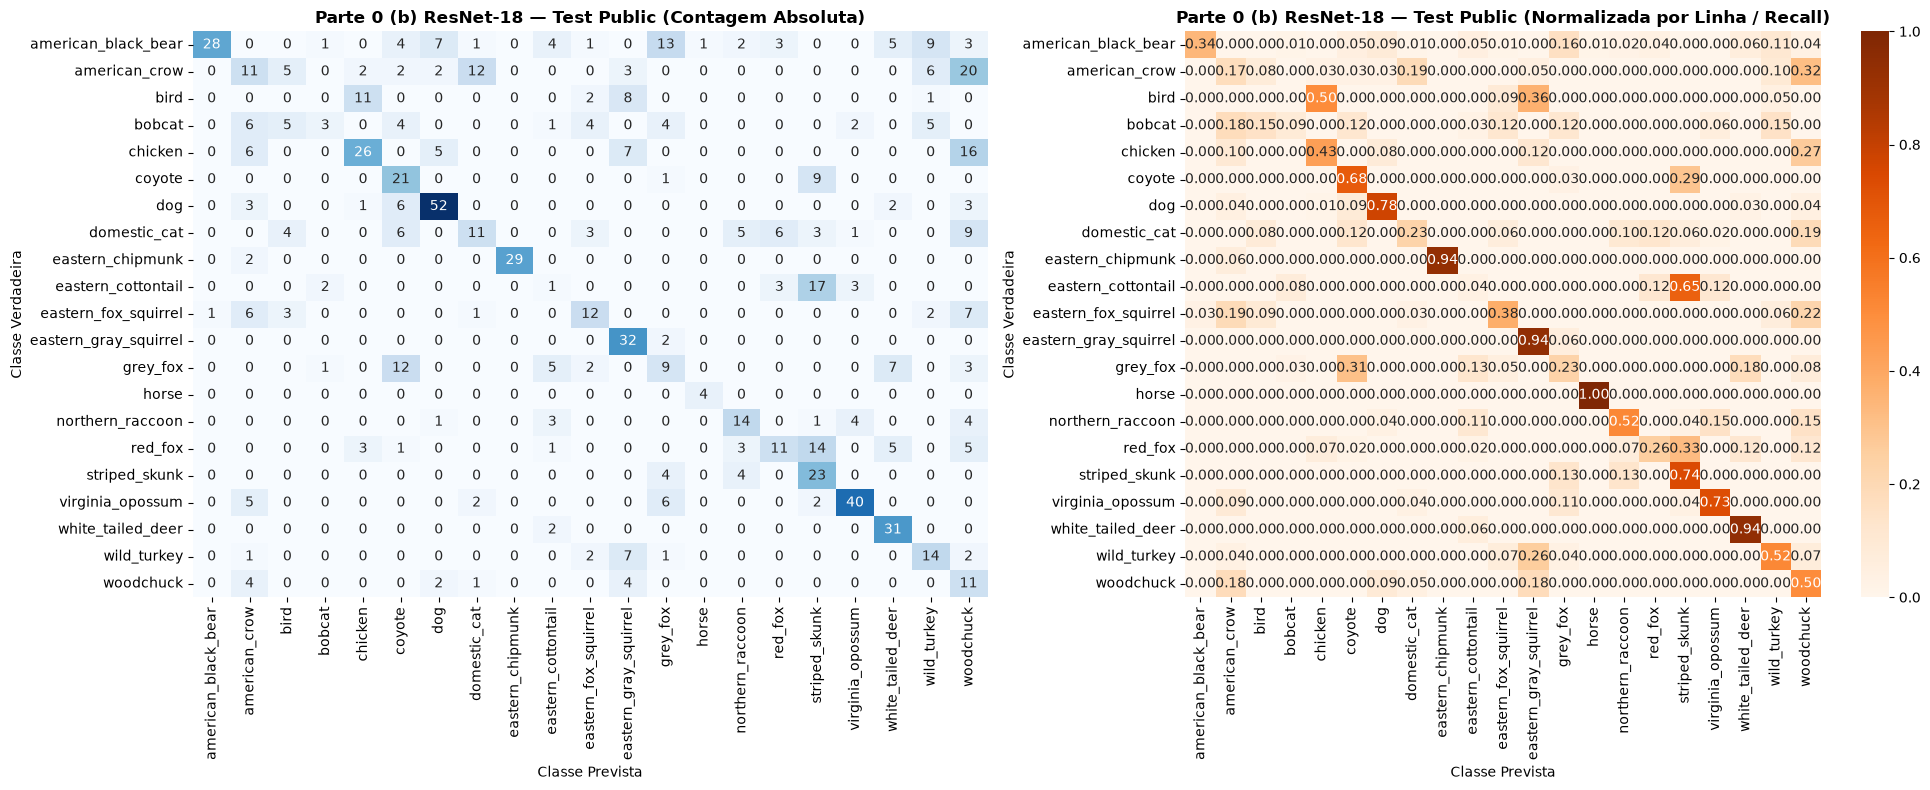

In [23]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints de (a) e (b) no test_public
test_metrics_cnn = evaluate(cnn_zero, test_loader, criterion, device)
test_metrics_res = evaluate(resnet_piso, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "0.1 (a) SmallCNN (do zero)",
        "Parâmetros": count_parameters(cnn_zero),
        "Val F1 Macro (Melhor)": round(hist_cnn["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_cnn["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_cnn["acc"], 4),
    },
    {
        "Modelo": "0.1 (b) ResNet-18 (ImageNet Fine-Tuning)",
        "Parâmetros": count_parameters(resnet_piso),
        "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_res["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_res["acc"], 4),
    }
])
print("Comparativo da Parte 0 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

# Salva o resultado oficial do piso (b) no curva_orcamento.csv
df_orc = log_budget_result(
    csv_path="curva_orcamento.csv",
    metodo="piso",
    orcamento=5,
    seed=42,
    f1_macro=test_metrics_res["f1_macro"],
    acuracia=test_metrics_res["acc"]
)

# Plota a Matriz de Confusão da versão (b) no test_public
plot_confusion_matrix(
    y_true=test_metrics_res["y_true"],
    y_pred=test_metrics_res["y_pred"],
    class_names=class_names,
    title="Parte 0 (b) ResNet-18 — Test Public",
    save_fig="figures/parte0_matriz_confusao_resnet18.png"
)

### 0.3: Curva de treino e validação da versão (b) — Em que época ela começa a decorar?

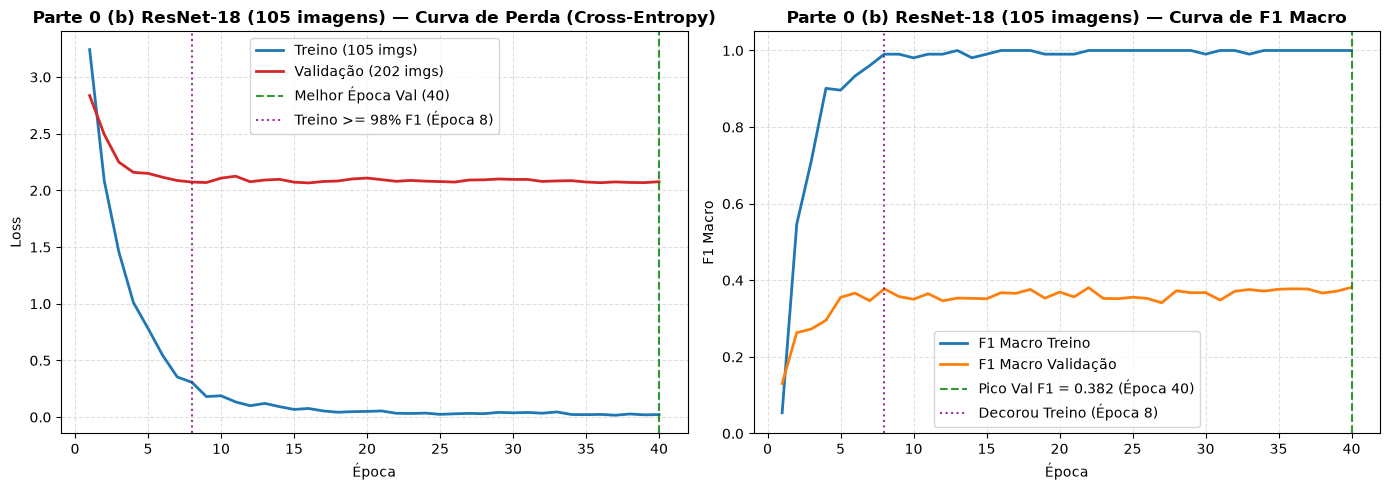

Época em que o treino atingiu >= 98% de F1 Macro: Época 8
Época de pico do F1 Macro na validação:  Época 40


In [24]:
plot_learning_curves(
    hist_resnet,
    title_prefix="Parte 0 (b) ResNet-18 (105 imagens)",
    save_fig="figures/parte0_curvas_resnet18.png"
)

# Diagnóstico numérico automático para responder à pergunta 0.3:
mem_rows = hist_resnet[hist_resnet["train_f1_macro"] >= 0.98]
ep_decorou = int(mem_rows.iloc[0]["epoch"]) if len(mem_rows) > 0 else "N/A"
ep_melhor_val = hist_resnet.attrs["best_epoch"]

print(f"Época em que o treino atingiu >= 98% de F1 Macro: Época {ep_decorou}")
print(f"Época de pico do F1 Macro na validação:  Época {ep_melhor_val}")

# Parte 1 — Usando o que não tem rótulo (escolham UMA trilha):